# Setup & Reproduksibilitas

In [1]:
import random, json, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix
from scipy.stats import binomtest
import matplotlib.pyplot as plt

SEED = 42

def set_seed(seed=None):
  seed = SEED if seed is None else seed
  random.seed(seed); np.random.seed(seed)
  torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False

print("success")

success


In [2]:
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device: ", device)

RESULTS = {}

def save_results(path="results.json"):
  with open(path, "w") as f:
    json.dump(RESULTS, f, indent=2)

Device:  cuda


# Data & Split Stratified

In [3]:
# transform=None karna kita akan baca gambar sendiri
ds_trainval = OxfordIIITPet(root="data", split="trainval", target_types="category", download=True)
ds_test = OxfordIIITPet(root="data", split="test", target_types="category", download=True)

print("success")

100%|██████████| 792M/792M [00:38<00:00, 20.8MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.31MB/s]


success


In [4]:
# gabungkan: kita buat split 70/15/15 sendiri
all_paths = list(ds_trainval._images) + list(ds_test._images)
all_labels = list(ds_trainval._labels) + list(ds_test._labels)
all_classes = ds_trainval.classes

print(len(all_paths), "gambar,", len(all_classes), "kelas")
for i, c in enumerate(all_classes):
  print(i, c)

7349 gambar, 37 kelas
0 Abyssinian
1 American Bulldog
2 American Pit Bull Terrier
3 Basset Hound
4 Beagle
5 Bengal
6 Birman
7 Bombay
8 Boxer
9 British Shorthair
10 Chihuahua
11 Egyptian Mau
12 English Cocker Spaniel
13 English Setter
14 German Shorthaired
15 Great Pyrenees
16 Havanese
17 Japanese Chin
18 Keeshond
19 Leonberger
20 Maine Coon
21 Miniature Pinscher
22 Newfoundland
23 Persian
24 Pomeranian
25 Pug
26 Ragdoll
27 Russian Blue
28 Saint Bernard
29 Samoyed
30 Scottish Terrier
31 Shiba Inu
32 Siamese
33 Sphynx
34 Staffordshire Bull Terrier
35 Wheaten Terrier
36 Yorkshire Terrier


In [5]:
# pilih 10 kelas dan remap label
CHOSEN = [
    # kucing
    "Abyssinian", "Bengal", "Egyptian Mau", "Birman", "Ragdoll",
    # anjing
    "American Pit Bull Terrier", "Staffordshire Bull Terrier",
    "Beagle", "Basset Hound", "English Cocker Spaniel",
]

# validasi nama
missing = [c for c in CHOSEN if c not in all_classes]
assert not missing, f"Nama tidak ditemukan: {missing}."

old2new = {all_classes.index(c): new for new, c in enumerate(CHOSEN)}

paths = [p for p, l in zip(all_paths, all_labels) if l in old2new]
labels = [old2new[l] for l in all_labels if l in old2new]

print("Total subset: ", len(paths), "gambar")
print("Per kelas: ", np.bincount(labels))

Total subset:  1973 gambar
Per kelas:  [198 200 190 200 200 200 189 200 200 196]


In [6]:
# splitting dataset
p_train, p_temp, y_train, y_temp = train_test_split(
    paths, labels, test_size=0.3, stratify=labels, random_state=SEED
)

p_val, p_test, y_val, y_test = train_test_split(
    p_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED
)

print("Train: ", len(p_train), "gambar")
print("Val: ", len(p_val), "gambar")
print("Test: ", len(p_test), "gambar")

# cek leakage
assert not (set(p_train) & set(p_val))
assert not (set(p_train) & set(p_test))
assert not (set(p_val) & set(p_test))
print("Tidak ada overlap antar split")

Train:  1381 gambar
Val:  296 gambar
Test:  296 gambar
Tidak ada overlap antar split


In [7]:
# dataset class dan transforms
class PetDataset(Dataset):
  def __init__(self, paths, labels, transform):
    self.paths = paths
    self.labels = labels
    self.transform = transform

  def __len__(self):
    return len(self.paths)

  def __getitem__(self, i):
    img = Image.open(self.paths[i]).convert("RGB")
    return self.transform(img), self.labels[i]

weights = models.ResNet18_Weights.IMAGENET1K_V1
mean, std = weights.transforms().mean, weights.transforms().std

# evaluasi tanpa augmentasi
eval_tf = weights.transforms()

# dengan augmentasi
train_tf_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [8]:
# train
train_ds_aug = PetDataset(p_train, y_train, train_tf_aug)
train_ds_noaug = PetDataset(p_train, y_train, eval_tf)

# val
val_ds = PetDataset(p_val, y_val, eval_tf)

# test
test_ds = PetDataset(p_test, y_test, eval_tf)

In [9]:
# data loader
def seed_worker(worker_id):
  s = torch.initial_seed() % 2**32
  np.random.seed(s); random.seed(s)

def make_loader(ds, shuffle, bs=32):
  g = torch.Generator(); g.manual_seed(SEED)
  return DataLoader(
      ds, batch_size=bs, shuffle=shuffle, num_workers=2,
      worker_init_fn=seed_worker, generator=g, pin_memory=True
  )

val_loader = make_loader(val_ds, shuffle=False)
test_loader = make_loader(test_ds, shuffle=False)

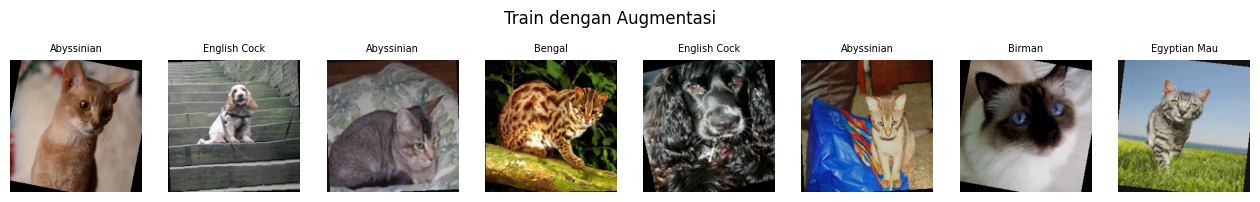

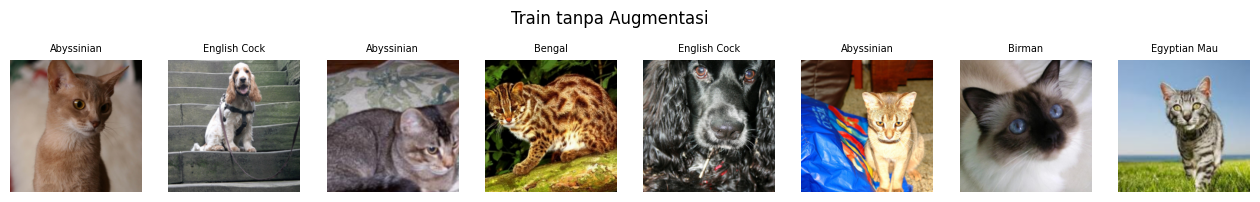

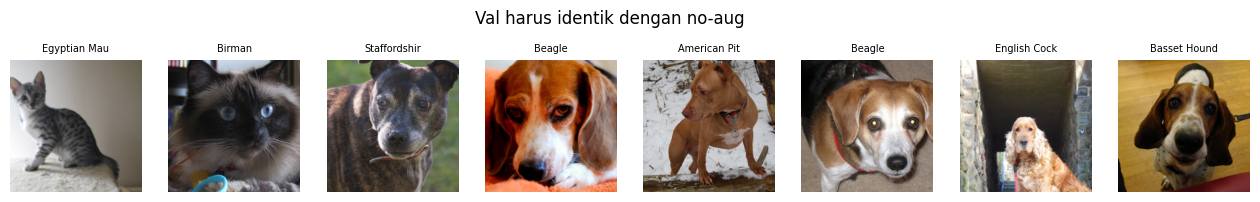

In [10]:
# sanity check visual
inv = transforms.Normalize(mean=[-m/s for m, s in zip(mean, std)], std=[1/s for s in std])

def show_batch(ds, n=8, title=""):
  fig, axes = plt.subplots(1, n, figsize=(2*n, 2.4))
  for ax, i in zip(axes, range(n)):
    x, y = ds[i]
    ax.imshow(inv(x).clamp(0, 1).permute(1, 2, 0)); ax.axis("off")
    ax.set_title(CHOSEN[y][:12], fontsize=7)
  fig.suptitle(title); plt.show()

show_batch(train_ds_aug, title="Train dengan Augmentasi")
show_batch(train_ds_noaug, title="Train tanpa Augmentasi")
show_batch(val_ds, title="Val harus identik dengan no-aug")

# Fungsi Training Generik

In [11]:
# hitung parameter dan evaluasi
criterion = nn.CrossEntropyLoss()

def count_params(model):
  trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
  total = sum(p.numel() for p in model.parameters())
  return trainable, total

@torch.no_grad()
def evaluate(model, loader):
  model.eval()
  total_loss = 0.0
  preds, labels, probs = [], [], []
  for x, y in loader:
    x, y = x.to(device), y.to(device)
    out = model(x)
    total_loss += criterion(out, y).item() * x.size(0)
    probs.append(F.softmax(out, dim=1).cpu())
    preds.append(out.argmax(1).cpu())
    labels.append(y.cpu())
  preds, labels, probs = torch.cat(preds), torch.cat(labels), torch.cat(probs)
  return {
      "loss": total_loss / len(labels),
      "acc": (preds == labels).float().mean().item(),
      "preds": preds, "labels": labels, "probs": probs
  }

In [12]:
# satu epoch training dengan BN beku
def train_one_epoch(model, loader, optimizer, eval_modules):
  model.train()

  for m in eval_modules:
    m.eval()

  total_loss, correct, n = 0.0, 0, 0

  for x, y in loader:
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    out = model(x)
    loss = criterion(out, y)
    loss.backward()
    optimizer.step()
    total_loss += loss.item() * x.size(0)
    correct += (out.argmax(1) == y).sum().item()
    n += x.size(0)

  return total_loss / n, correct / n

In [13]:
def run_experiment(name, model, optimizer, train_ds, eval_modules=(),
                   max_epochs=30, patience=5, min_delta=1e-4):
  model.to(device)
  train_loader = make_loader(train_ds, shuffle=True)
  train_clean_loader = make_loader(train_ds_noaug, shuffle=False)   # untuk ukur train acc bersih

  trainable, total = count_params(model)
  lrs = [g["lr"] for g in optimizer.param_groups]
  print(f"[{name}] trainable {trainable:,} / {total:,} | lr per group: {lrs}")

  history = []
  best_val, best_state, best_epoch, wait = float("inf"), None, 0, 0

  if device.type == "cuda":
    torch.cuda.synchronize()
  t0 = time.time()
  for epoch in range(1, max_epochs + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, eval_modules)
    val = evaluate(model, val_loader)
    history.append({"epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc,
                    "val_loss": val["loss"], "val_acc": val["acc"]})
    print(f"epoch {epoch:02d} | tr_loss {tr_loss:.4f} tr_acc {tr_acc:.3f} | "
          f"val_loss {val['loss']:.4f} val_acc {val['acc']:.3f}")

    if val["loss"] < best_val - min_delta:
      best_val, best_epoch, wait = val["loss"], epoch, 0
      best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
      wait += 1
      if wait >= patience:
        print(f" early stop di epoch {epoch} (best {best_epoch})")
        break

  if device.type == "cuda": torch.cuda.synchronize()
  train_time = time.time() - t0

  model.load_state_dict(best_state)
  train_clean = evaluate(model, train_clean_loader)
  val = evaluate(model, val_loader)
  test = evaluate(model, test_loader)
  macro_f1 = f1_score(test["labels"], test["preds"], average="macro")

  RESULTS[name] = {
      "trainable_params": trainable, "total_params": total,
      "lr_per_group": lrs, "seed": SEED,
      "best_epoch": best_epoch, "epochs_run": len(history),
      "train_time_sec": round(train_time, 1),
      "train_acc_clean": train_clean["acc"], "val_acc": val["acc"],
      "val_loss": val["loss"], "test_acc": test["acc"], "test_macro_f1": macro_f1,
      "gap_train_val": train_clean["acc"] - val["acc"],
      "history": history,
  }

  save_results()

  print(f"[{name}] val_acc {val['acc']:.4f} | test macro-F1 {macro_f1:.4f} | "
          f"{train_time:.0f}s | best_epoch {best_epoch}")

  return {"model": model, "test": test, "history": history}

In [14]:
# builder untuk B2 dan smoke test

def build_b2():
  set_seed()
  m = models.resnet18(weights=weights)
  for p in m.parameters():
    p.requires_grad = False
  m.fc = nn.Linear(m.fc.in_features, 10)
  opt = torch.optim.AdamW(m.fc.parameters(), lr=1e-3, weight_decay=1e-2)
  eval_mods = [m.conv1, m.bn1, m.layer1, m.layer2, m.layer3, m.layer4]
  return m, opt, eval_mods

m, opt, em = build_b2()
trainable, total = count_params(m)
assert trainable == 5130, trainable   # 512*10 + 10
print("OK:", trainable, "/", total)

# Smoke test 2 epoch
_ = run_experiment("smoke_B2", m, opt, train_ds_noaug, eval_modules=em, max_epochs=2)
RESULTS.pop("smoke_B2"); save_results()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


OK: 5130 / 11181642
[smoke_B2] trainable 5,130 / 11,181,642 | lr per group: [0.001]
epoch 01 | tr_loss 1.3180 tr_acc 0.590 | val_loss 0.7445 val_acc 0.777
epoch 02 | tr_loss 0.5604 tr_acc 0.852 | val_loss 0.4823 val_acc 0.848
[smoke_B2] val_acc 0.8480 | test macro-F1 0.8405 | 24s | best_epoch 2


# Sanity Check Pipeline

In [15]:
x1, x2 = train_ds_aug[0][0], train_ds_aug[0][0]
assert not torch.equal(x1, x2)

v1, v2 = val_ds[0][0], val_ds[0][0]
assert torch.equal(v1, v2)
print("Pipeline aug/val sesuai")

Pipeline aug/val sesuai


In [16]:
bn_changed = {}
for label, use_eval in [("dengan .eval() pada backbone", True), ("tanpa .eval()", False)]:
  mt, _, em = build_b2()
  before = mt.layer1[0].bn1.running_mean.clone()
  mt.to(device)
  o = torch.optim.AdamW(mt.fc.parameters(), lr=1e-3)
  train_one_epoch(mt, make_loader(train_ds_noaug, True), o, em if use_eval else [])
  bn_changed[use_eval] = not torch.equal(before, mt.layer1[0].bn1.running_mean.cpu())
  print(f"{label:32s} -> running_mean berubah: {bn_changed[use_eval]}")
assert bn_changed[True] is False and bn_changed[False] is True

dengan .eval() pada backbone     -> running_mean berubah: False
tanpa .eval()                    -> running_mean berubah: True


# B1-B3: Eksperimen Utama
- B1-B3 memakai augmentasi train yang sama sebagai kontrol. Efek augmentasi diuji terpisah di B4, hanya pada B3.
- BatchNorm di backbone beku dipaksa `.eval()`, karena `requires_grad=False` tidak menghentikan update running statistics (dibuktikan di cell cek BN).
- Model untuk failure analysis dipilih dari val accuracy, bukan test.

In [17]:
# builder b1 dan b3
MAX_EPOCHS, PATIENCE = 40, 5

def build_b1():
  set_seed()
  m = models.resnet18(weights=None)
  m.fc = nn.Linear(m.fc.in_features, 10)
  opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-2)
  return m, opt, []

def build_b3():
  set_seed()
  m = models.resnet18(weights=weights)
  for p in m.parameters():
    p.requires_grad = False
  for p in m.layer4.parameters():
    p.requires_grad = True
  m.fc = nn.Linear(m.fc.in_features, 10)
  opt = torch.optim.AdamW([
      {"params": m.layer4.parameters(), "lr": 1e-4},
      {"params": m.fc.parameters(), "lr": 1e-3},
  ], weight_decay=1e-2)
  eval_mods = [m.conv1, m.bn1, m.layer1, m.layer2, m.layer3]
  return m, opt, eval_mods

CONFIG = {"seed": SEED, "classes": CHOSEN,
          "split": {"train": len(p_train), "val": len(p_val), "test": len(p_test)},
          "batch_size": 32, "optimizer": "AdamW(weight_decay=1e-2)",
          "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
          "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
          "torch": torch.__version__, "torchvision": torchvision.__version__}
json.dump(CONFIG, open("config.json", "w"), indent=2)

In [18]:
# hitungan manual untuk memverifikasi
EXPECTED = {"B1": 11_181_642, "B2": 5_130, "B3": 8_398_858}
builders = {"B1": build_b1, "B2": build_b2, "B3": build_b3}

out = {}
for name, build in builders.items():
  m, opt, em = build()
  trainable, total = count_params(m)
  assert trainable == EXPECTED[name], f"{name}: {trainable:,} != {EXPECTED[name]:,}"
  out[name] = run_experiment(name, m, opt, train_ds_aug, eval_modules=em, max_epochs=MAX_EPOCHS, patience=PATIENCE)

[B1] trainable 11,181,642 / 11,181,642 | lr per group: [0.001]
epoch 01 | tr_loss 2.3836 tr_acc 0.169 | val_loss 2.6714 val_acc 0.203
epoch 02 | tr_loss 2.1053 tr_acc 0.243 | val_loss 2.8000 val_acc 0.176
epoch 03 | tr_loss 1.9884 tr_acc 0.291 | val_loss 2.4244 val_acc 0.250
epoch 04 | tr_loss 1.9412 tr_acc 0.302 | val_loss 2.2527 val_acc 0.274
epoch 05 | tr_loss 1.8981 tr_acc 0.306 | val_loss 1.7690 val_acc 0.361
epoch 06 | tr_loss 1.7970 tr_acc 0.348 | val_loss 2.5484 val_acc 0.213
epoch 07 | tr_loss 1.7681 tr_acc 0.366 | val_loss 1.9048 val_acc 0.321
epoch 08 | tr_loss 1.7781 tr_acc 0.370 | val_loss 1.7561 val_acc 0.389
epoch 09 | tr_loss 1.7676 tr_acc 0.375 | val_loss 2.2467 val_acc 0.247
epoch 10 | tr_loss 1.6763 tr_acc 0.401 | val_loss 1.7398 val_acc 0.361
epoch 11 | tr_loss 1.6409 tr_acc 0.400 | val_loss 1.6997 val_acc 0.385
epoch 12 | tr_loss 1.5540 tr_acc 0.440 | val_loss 1.7760 val_acc 0.405
epoch 13 | tr_loss 1.5695 tr_acc 0.418 | val_loss 1.6442 val_acc 0.399
epoch 14 | tr_

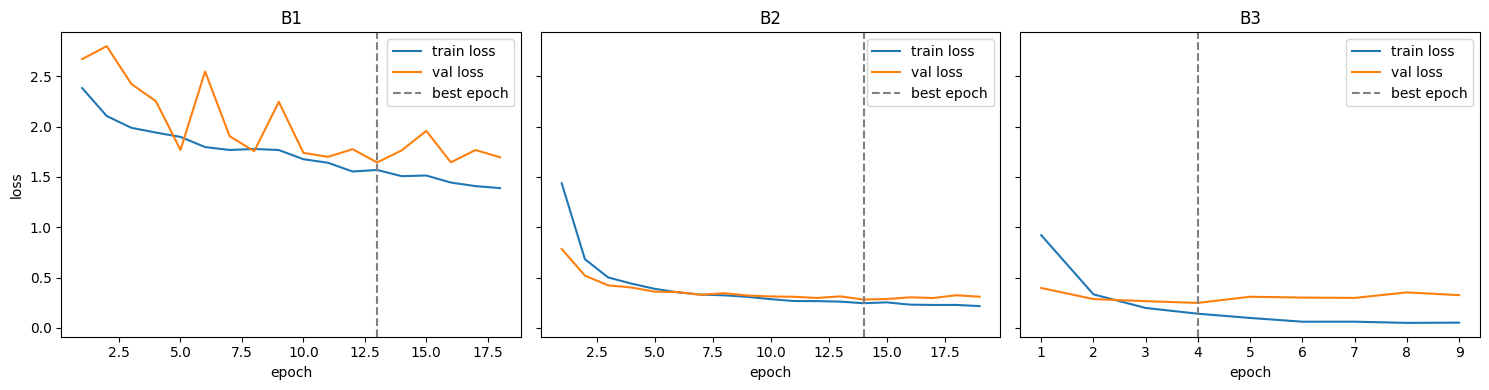

   trainable_params best_epoch epochs_run train_time_sec train_acc_clean  \
B1         11181642         13         18          266.5        0.451846   
B2             5130         14         19          261.1        0.940623   
B3          8398858          4          9          125.4        0.979001   

     val_acc test_macro_f1 gap_train_val  
B1  0.398649      0.411431      0.053198  
B2  0.885135      0.891739      0.055488  
B3  0.902027      0.894926      0.076974  


In [19]:
# kurva loss dan tabel summary
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, ["B1", "B2", "B3"]):
  h = RESULTS[name]["history"]
  ep = [r["epoch"] for r in h]
  ax.plot(ep, [r["train_loss"] for r in h], label="train loss")
  ax.plot(ep, [r["val_loss"] for r in h], label="val loss")
  ax.axvline(RESULTS[name]["best_epoch"], ls="--", c="gray", label="best epoch")
  ax.set_title(name); ax.set_xlabel("epoch"); ax.legend()

axes[0].set_ylabel("loss")
plt.tight_layout(); plt.savefig("curves_B1_B2_B3.png", dpi=150); plt.show()

cols = ["trainable_params", "best_epoch", "epochs_run", "train_time_sec",
        "train_acc_clean", "val_acc", "test_macro_f1", "gap_train_val"]
print(pd.DataFrame(RESULTS).T[cols])

In [20]:
# McNemar: B2 vs B3 pada test set
t2, t3 = out["B2"]["test"], out["B3"]["test"]
c2 = (t2["preds"] == t2["labels"]); c3 = (t3["preds"] == t3["labels"])
b_cnt = int((c2 & ~c3).sum()); c_cnt = int((~c2 & c3).sum())
mc_p = binomtest(min(b_cnt, c_cnt), b_cnt + c_cnt, 0.5).pvalue if (b_cnt + c_cnt) else 1.0
print("B2 benar - B3 salah:", b_cnt, "| B2 salah - B3 benar:", c_cnt, "| p-value (exact):", round(mc_p, 4))

B2 benar - B3 salah: 13 | B2 salah - B3 benar: 14 | p-value (exact): 1.0


In [21]:
# B1_ext: analisis sensitivitas
m, opt, em = build_b1()
out["B1_ext"] = run_experiment("B1_ext", m, opt, train_ds_aug, eval_modules=em, max_epochs=60, patience=10)

[B1_ext] trainable 11,181,642 / 11,181,642 | lr per group: [0.001]
epoch 01 | tr_loss 2.3836 tr_acc 0.169 | val_loss 2.6714 val_acc 0.203
epoch 02 | tr_loss 2.1053 tr_acc 0.243 | val_loss 2.8000 val_acc 0.176
epoch 03 | tr_loss 1.9884 tr_acc 0.291 | val_loss 2.4244 val_acc 0.250
epoch 04 | tr_loss 1.9412 tr_acc 0.302 | val_loss 2.2527 val_acc 0.274
epoch 05 | tr_loss 1.8981 tr_acc 0.306 | val_loss 1.7690 val_acc 0.361
epoch 06 | tr_loss 1.7970 tr_acc 0.348 | val_loss 2.5484 val_acc 0.213
epoch 07 | tr_loss 1.7681 tr_acc 0.366 | val_loss 1.9048 val_acc 0.321
epoch 08 | tr_loss 1.7781 tr_acc 0.370 | val_loss 1.7561 val_acc 0.389
epoch 09 | tr_loss 1.7676 tr_acc 0.375 | val_loss 2.2467 val_acc 0.247
epoch 10 | tr_loss 1.6763 tr_acc 0.401 | val_loss 1.7398 val_acc 0.361
epoch 11 | tr_loss 1.6409 tr_acc 0.400 | val_loss 1.6997 val_acc 0.385
epoch 12 | tr_loss 1.5540 tr_acc 0.440 | val_loss 1.7760 val_acc 0.405
epoch 13 | tr_loss 1.5695 tr_acc 0.418 | val_loss 1.6442 val_acc 0.399
epoch 14 |

# B4: Uji Kontrol Augmentasi

[B4_B3_noaug] trainable 8,398,858 / 11,181,642 | lr per group: [0.0001, 0.001]
epoch 01 | tr_loss 0.8195 tr_acc 0.747 | val_loss 0.3514 val_acc 0.855
epoch 02 | tr_loss 0.1702 tr_acc 0.955 | val_loss 0.2834 val_acc 0.892
epoch 03 | tr_loss 0.0604 tr_acc 0.994 | val_loss 0.2757 val_acc 0.895
epoch 04 | tr_loss 0.0271 tr_acc 0.998 | val_loss 0.2650 val_acc 0.909
epoch 05 | tr_loss 0.0220 tr_acc 0.999 | val_loss 0.2857 val_acc 0.895
epoch 06 | tr_loss 0.0094 tr_acc 1.000 | val_loss 0.2818 val_acc 0.895
epoch 07 | tr_loss 0.0073 tr_acc 1.000 | val_loss 0.2812 val_acc 0.905
epoch 08 | tr_loss 0.0053 tr_acc 1.000 | val_loss 0.2791 val_acc 0.902
epoch 09 | tr_loss 0.0061 tr_acc 1.000 | val_loss 0.2913 val_acc 0.902
 early stop di epoch 9 (best 4)
[B4_B3_noaug] val_acc 0.9088 | test macro-F1 0.8980 | 91s | best_epoch 4
            best_epoch train_acc_clean   val_acc test_macro_f1 gap_train_val
B3                   4        0.979001  0.902027      0.894926      0.076974
B4_B3_noaug          4 

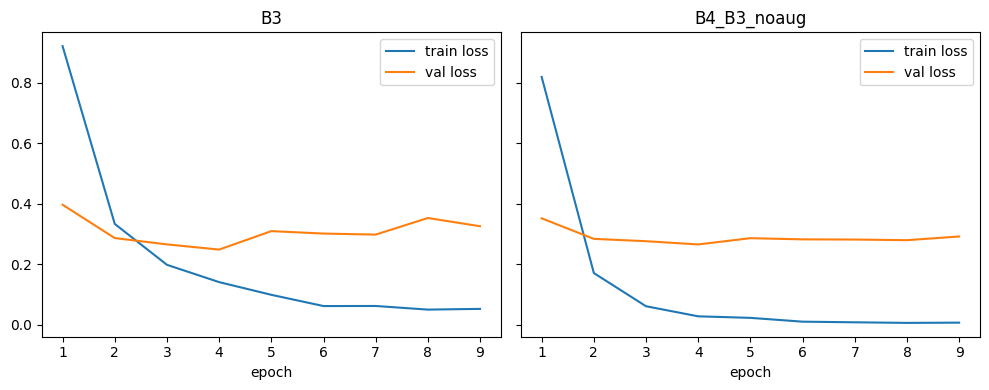

In [22]:
# augmentasi dan arsitektur pembanding
m, opt, em = build_b3()
out["B4_B3_noaug"] = run_experiment("B4_B3_noaug", m, opt, train_ds_noaug,
                                    eval_modules=em, max_epochs=MAX_EPOCHS, patience=PATIENCE)

cols = ["best_epoch", "train_acc_clean", "val_acc", "test_macro_f1", "gap_train_val"]
print(pd.DataFrame({k: RESULTS[k] for k in ["B3", "B4_B3_noaug"]}).T[cols])

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, name in zip(axes, ["B3", "B4_B3_noaug"]):
  h = RESULTS[name]["history"]; ep = [r["epoch"] for r in h]
  ax.plot(ep, [r["train_loss"] for r in h], label="train loss")
  ax.plot(ep, [r["val_loss"] for r in h], label="val loss")
  ax.set_title(name); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig("curves_B4.png", dpi=150); plt.show()

# B5: Arsitektur Pembanding
Catatan: "2 blok terakhir" pada EfficientNet-B0 / MobileNetV3-S bukan padanan persis layer4 ResNet-18.
Fraksi parameter yang dilatih berbeda (EfficientNet-B0 28%, MobileNetV3-S 62%, ResNet-18 B3 75%).
Perbandingan B5 hanya single seed (42).

In [23]:
def build_b5(arch, k=2):
  set_seed()
  if arch == "efficientnet_b0":
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
  else:
    m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)

  for p in m.parameters():
    p.requires_grad = False

  low = [p for blk in list(m.features[-k:]) + list(m.classifier[:-1]) for p in blk.parameters()]

  for p in low:
    p.requires_grad = True

  m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 10)

  opt = torch.optim.AdamW([
      {"params": low, "lr": 1e-4},
      {"params": m.classifier[-1].parameters(), "lr": 1e-3},
  ], weight_decay=1e-2)

  return m, opt, [m.features[:-k]]


@torch.no_grad()
def bench_latency(model, bs=32, n_warm=10, n_iter=50):
  model.eval().to(device)
  x = torch.randn(bs, 3, 224, 224, device=device)
  for _ in range(n_warm): model(x)
  torch.cuda.synchronize(); t0 = time.time()
  for _ in range(n_iter): model(x)
  torch.cuda.synchronize()
  return (time.time() - t0) / n_iter * 1000

for arch in ["efficientnet_b0", "mobilenet_v3_small"]:
  m, opt, em = build_b5(arch)
  print(arch, "trainable/total:", count_params(m))
  out[f"B5_{arch}"] = run_experiment(f"B5_{arch}", m, opt, train_ds_aug,
                                     eval_modules=em, max_epochs=MAX_EPOCHS, patience=PATIENCE)
  RESULTS[f"B5_{arch}"]["latency_ms_b32"] = bench_latency(m)
save_results()

m, _, _ = build_b3()
RESULTS["B3"]["latency_ms_b32"] = bench_latency(m); save_results()

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 186MB/s]

efficientnet_b0 trainable/total: (1142202, 4020358)
[B5_efficientnet_b0] trainable 1,142,202 / 4,020,358 | lr per group: [0.0001, 0.001]


epoch 01 | tr_loss 1.1385 tr_acc 0.710 | val_loss 0.4025 val_acc 0.902
epoch 02 | tr_loss 0.3663 tr_acc 0.885 | val_loss 0.2911 val_acc 0.905
epoch 03 | tr_loss 0.2607 tr_acc 0.918 | val_loss 0.2467 val_acc 0.905
epoch 04 | tr_loss 0.1990 tr_acc 0.937 | val_loss 0.2146 val_acc 0.912
epoch 05 | tr_loss 0.1789 tr_acc 0.946 | val_loss 0.2193 val_acc 0.922
epoch 06 | tr_loss 0.1435 tr_acc 0.951 | val_loss 0.2259 val_acc 0.916
epoch 07 | tr_loss 0.1376 tr_acc 0.963 | val_loss 0.2153 val_acc 0.932
epoch 08 | tr_loss 0.0967 tr_acc 0.975 | val_loss 0.2057 val_acc 0.929
epoch 09 | tr_loss 0.0922 tr_acc 0.972 | val_loss 0.2039 val_acc 0.922
epoch 10 | tr_loss 0.0761 tr_acc 0.978 | val_loss 0.1888 val_acc 0.926
epoch 11 | tr_loss 0.0673 tr_acc 0.979 | val_loss 0.2113 val_acc 0.916
epoch 12 | tr_loss 0.0561 tr_acc 0.987 | val_loss 0.1969 val_acc 0.919
epoch 13 | tr_loss 0.0649 tr_acc 0.978 | val_loss 0.2118 val_acc 0.929
epoch 14 | tr_loss 0.0508 tr_acc 0.990 | val_loss 0.2067 val_acc 0.926
epoch 

100%|██████████| 9.83M/9.83M [00:00<00:00, 173MB/s]

mobilenet_v3_small trainable/total: (951642, 1528106)
[B5_mobilenet_v3_small] trainable 951,642 / 1,528,106 | lr per group: [0.0001, 0.001]


epoch 01 | tr_loss 1.2340 tr_acc 0.660 | val_loss 0.4671 val_acc 0.848
epoch 02 | tr_loss 0.4806 tr_acc 0.855 | val_loss 0.3454 val_acc 0.872
epoch 03 | tr_loss 0.3457 tr_acc 0.887 | val_loss 0.3368 val_acc 0.868
epoch 04 | tr_loss 0.2785 tr_acc 0.906 | val_loss 0.3101 val_acc 0.882
epoch 05 | tr_loss 0.2346 tr_acc 0.915 | val_loss 0.3102 val_acc 0.899
epoch 06 | tr_loss 0.2010 tr_acc 0.930 | val_loss 0.3441 val_acc 0.868
epoch 07 | tr_loss 0.1727 tr_acc 0.944 | val_loss 0.3573 val_acc 0.861
epoch 08 | tr_loss 0.1436 tr_acc 0.959 | val_loss 0.3483 val_acc 0.858
epoch 09 | tr_loss 0.1299 tr_acc 0.958 | val_loss 0.3273 val_acc 0.885
 early stop di epoch 9 (best 4)
[B5_mobilenet_v3_small] val_acc 0.8818 | test macro-F1 0.8945 | 120s | best_epoch 4


# Failure Analysis

Model failure analysis: B5_efficientnet_b0 | val acc: 0.9257
28 salah dari 296
8x  American Pit Bull Terrier -> Staffordshire Bull Terrier
6x  Ragdoll -> Birman
3x  Staffordshire Bull Terrier -> American Pit Bull Terrier
3x  Egyptian Mau -> Bengal
3x  Bengal -> Egyptian Mau
2x  Abyssinian -> Bengal


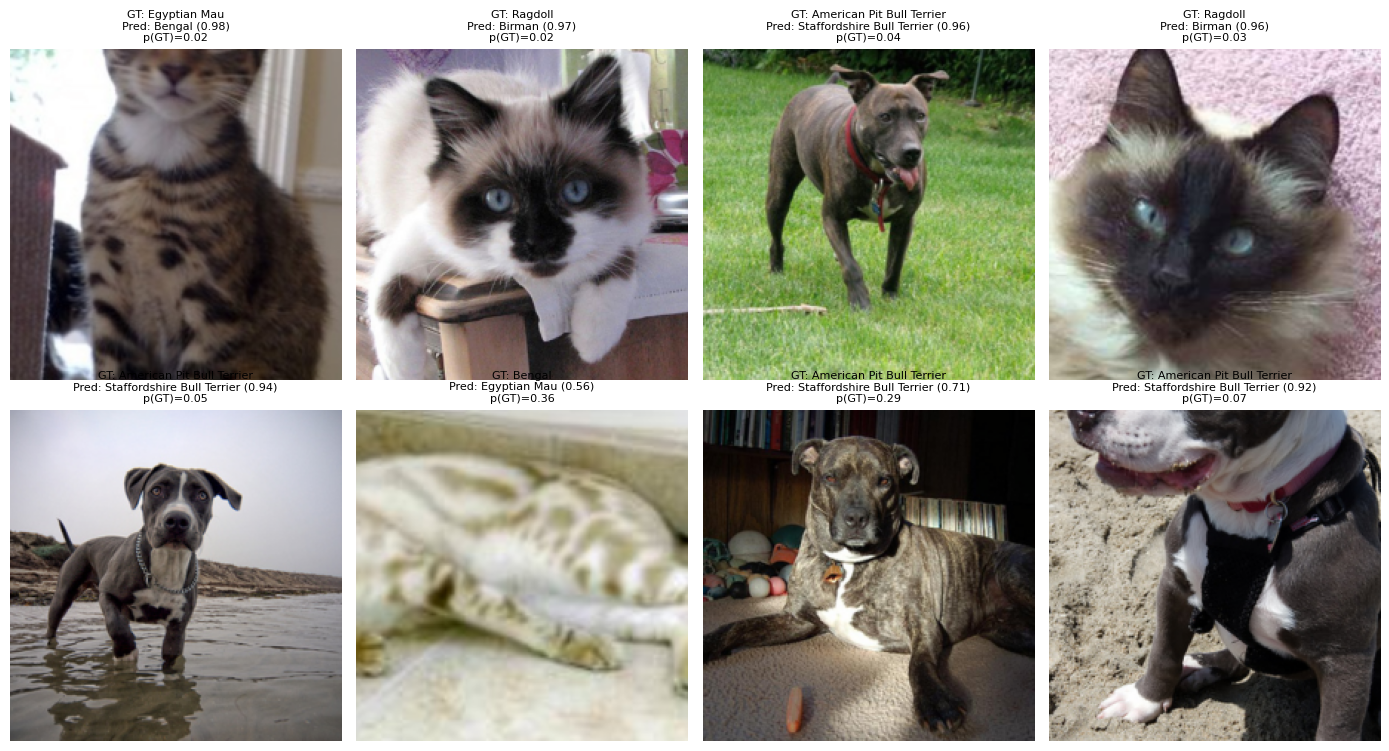

138 data/oxford-iiit-pet/images/Egyptian_Mau_84.jpg
210 data/oxford-iiit-pet/images/Ragdoll_136.jpg
102 data/oxford-iiit-pet/images/american_pit_bull_terrier_15.jpg
191 data/oxford-iiit-pet/images/Ragdoll_245.jpg
224 data/oxford-iiit-pet/images/american_pit_bull_terrier_88.jpg
92 data/oxford-iiit-pet/images/Bengal_135.jpg
212 data/oxford-iiit-pet/images/american_pit_bull_terrier_1.jpg
30 data/oxford-iiit-pet/images/american_pit_bull_terrier_46.jpg


In [24]:
# failure analysis
CANDIDATES = ["B2", "B3", "B4_B3_noaug", "B5_efficientnet_b0", "B5_mobilenet_v3_small"]
best_name = max(CANDIDATES, key=lambda k: RESULTS[k]["val_acc"])
print("Model failure analysis:", best_name, "| val acc:", round(RESULTS[best_name]["val_acc"], 4))

t = out[best_name]["test"]
y_true, y_pred, p_all = t["labels"].numpy(), t["preds"].numpy(), t["probs"].numpy()
conf_pred = p_all[np.arange(len(y_pred)), y_pred]
wrong_idx = np.where(y_pred != y_true)[0]
print(f"{len(wrong_idx)} salah dari {len(y_true)}")

cm = confusion_matrix(y_true, y_pred)
pairs = [(int(cm[i, j]), CHOSEN[i], CHOSEN[j]) for i in range(10) for j in range(10)
         if i != j and cm[i, j] > 0]
for n_err, a, b_ in sorted(pairs, reverse=True)[:6]:
  print(f"{n_err}x  {a} -> {b_}")

rng = np.random.RandomState(SEED)
by_conf = wrong_idx[np.argsort(-conf_pred[wrong_idx])]
rest = by_conf[5:]
idx = list(by_conf[:5]) + list(rng.choice(rest, size=min(3, len(rest)), replace=False))

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, i in zip(axes.ravel(), idx):
  x, _ = test_ds[i]
  ax.imshow(inv(x).clamp(0, 1).permute(1, 2, 0)); ax.axis("off")
  ax.set_title(f"GT: {CHOSEN[y_true[i]]}\nPred: {CHOSEN[y_pred[i]]} ({conf_pred[i]:.2f})\n"
               f"p(GT)={p_all[i, y_true[i]]:.2f}", fontsize=8)
plt.tight_layout(); plt.savefig("failure_analysis.png", dpi=150); plt.show()
for i in idx: print(i, p_test[i])

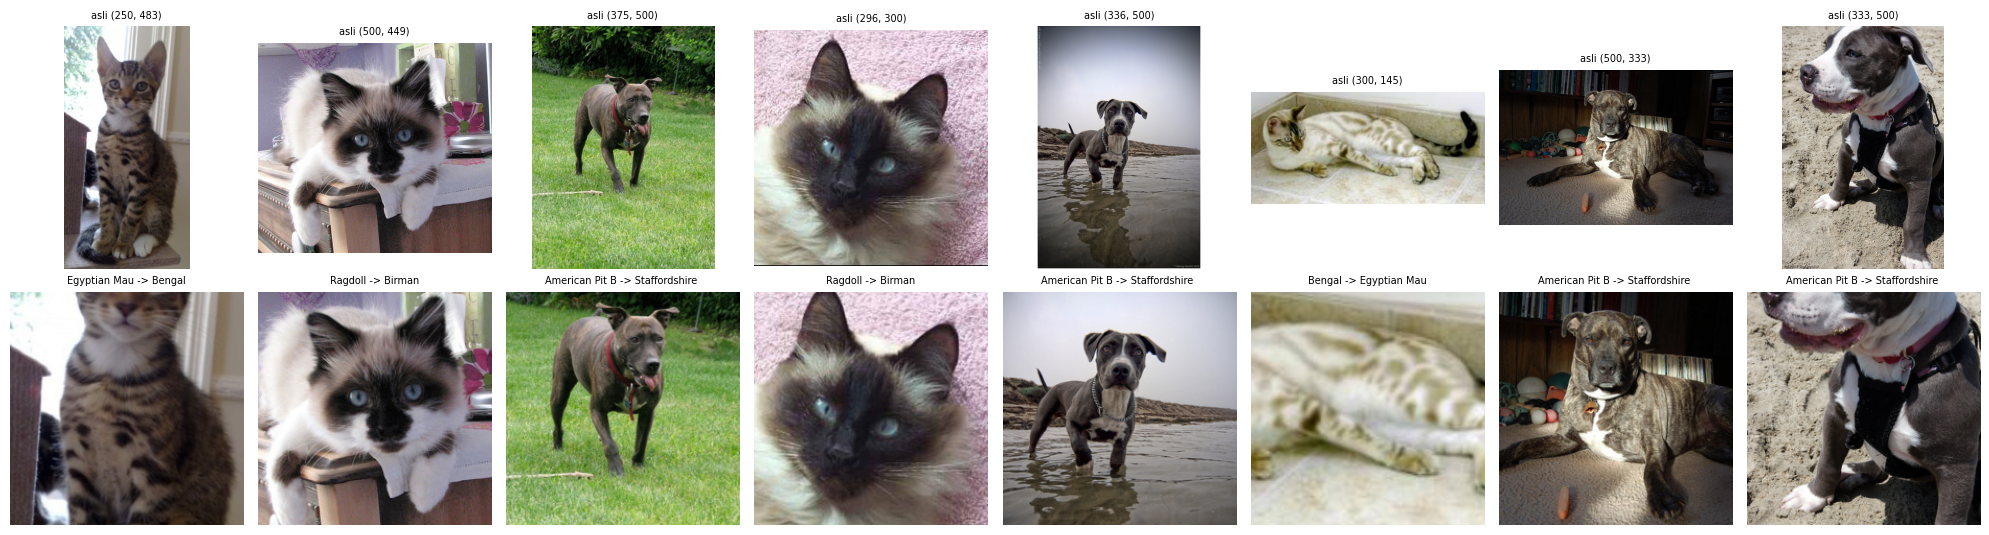

In [25]:
# uji hipotesis "objek terpotong" untuk failure analysis
fig, axes = plt.subplots(2, 8, figsize=(20, 5.5))
for k, i in enumerate(idx):
  im = Image.open(p_test[i]).convert("RGB"); x, _ = test_ds[i]
  axes[0, k].imshow(im); axes[0, k].set_title(f"asli {im.size}", fontsize=7); axes[0, k].axis("off")
  axes[1, k].imshow(inv(x).clamp(0, 1).permute(1, 2, 0))
  axes[1, k].set_title(f"{CHOSEN[y_true[i]][:14]} -> {CHOSEN[y_pred[i]][:14]}", fontsize=7); axes[1, k].axis("off")
plt.tight_layout(); plt.savefig("crop_check.png", dpi=150); plt.show()

# Multi-seed (n = 3)

In [26]:
runs = {"B2": (build_b2, train_ds_aug),
        "B3": (build_b3, train_ds_aug),
        "B4_noaug": (build_b3, train_ds_noaug)}

try:
  for s in [43, 44]:
    SEED = s
    for key, (build, ds) in runs.items():
      m, opt, em = build()
      run_experiment(f"{key}_s{s}", m, opt, ds, eval_modules=em,
                     max_epochs=MAX_EPOCHS, patience=PATIENCE)
finally:
  SEED = 42

name42 = {"B2": "B2", "B3": "B3", "B4_noaug": "B4_B3_noaug"}
rows = []
for key in runs:
  for s in [42, 43, 44]:
      r = RESULTS[name42[key]] if s == 42 else RESULTS[f"{key}_s{s}"]
      rows.append({"cond": key, "seed": s, "val_acc": r["val_acc"],
                     "test_f1": r["test_macro_f1"], "gap": r["gap_train_val"],
                     "best_epoch": r["best_epoch"]})
df = pd.DataFrame(rows)
print(df.pivot(index="seed", columns="cond", values="test_f1").round(4))
print(df.groupby("cond")[["val_acc", "test_f1", "gap", "best_epoch"]]
      .agg(["mean", "std"]).round(4))

[B2_s43] trainable 5,130 / 11,181,642 | lr per group: [0.001]
epoch 01 | tr_loss 1.3681 tr_acc 0.559 | val_loss 0.7312 val_acc 0.787
epoch 02 | tr_loss 0.6572 tr_acc 0.799 | val_loss 0.5011 val_acc 0.834
epoch 03 | tr_loss 0.4939 tr_acc 0.865 | val_loss 0.4398 val_acc 0.848
epoch 04 | tr_loss 0.4325 tr_acc 0.872 | val_loss 0.3808 val_acc 0.868
epoch 05 | tr_loss 0.3951 tr_acc 0.877 | val_loss 0.3566 val_acc 0.872
epoch 06 | tr_loss 0.3529 tr_acc 0.886 | val_loss 0.3527 val_acc 0.865
epoch 07 | tr_loss 0.3469 tr_acc 0.883 | val_loss 0.3288 val_acc 0.872
epoch 08 | tr_loss 0.3095 tr_acc 0.903 | val_loss 0.3085 val_acc 0.875
epoch 09 | tr_loss 0.2927 tr_acc 0.904 | val_loss 0.3182 val_acc 0.882
epoch 10 | tr_loss 0.2786 tr_acc 0.914 | val_loss 0.3281 val_acc 0.875
epoch 11 | tr_loss 0.2785 tr_acc 0.910 | val_loss 0.3000 val_acc 0.878
epoch 12 | tr_loss 0.2549 tr_acc 0.923 | val_loss 0.2881 val_acc 0.889
epoch 13 | tr_loss 0.2533 tr_acc 0.922 | val_loss 0.3202 val_acc 0.872
epoch 14 | tr_l

# Grad-CAM

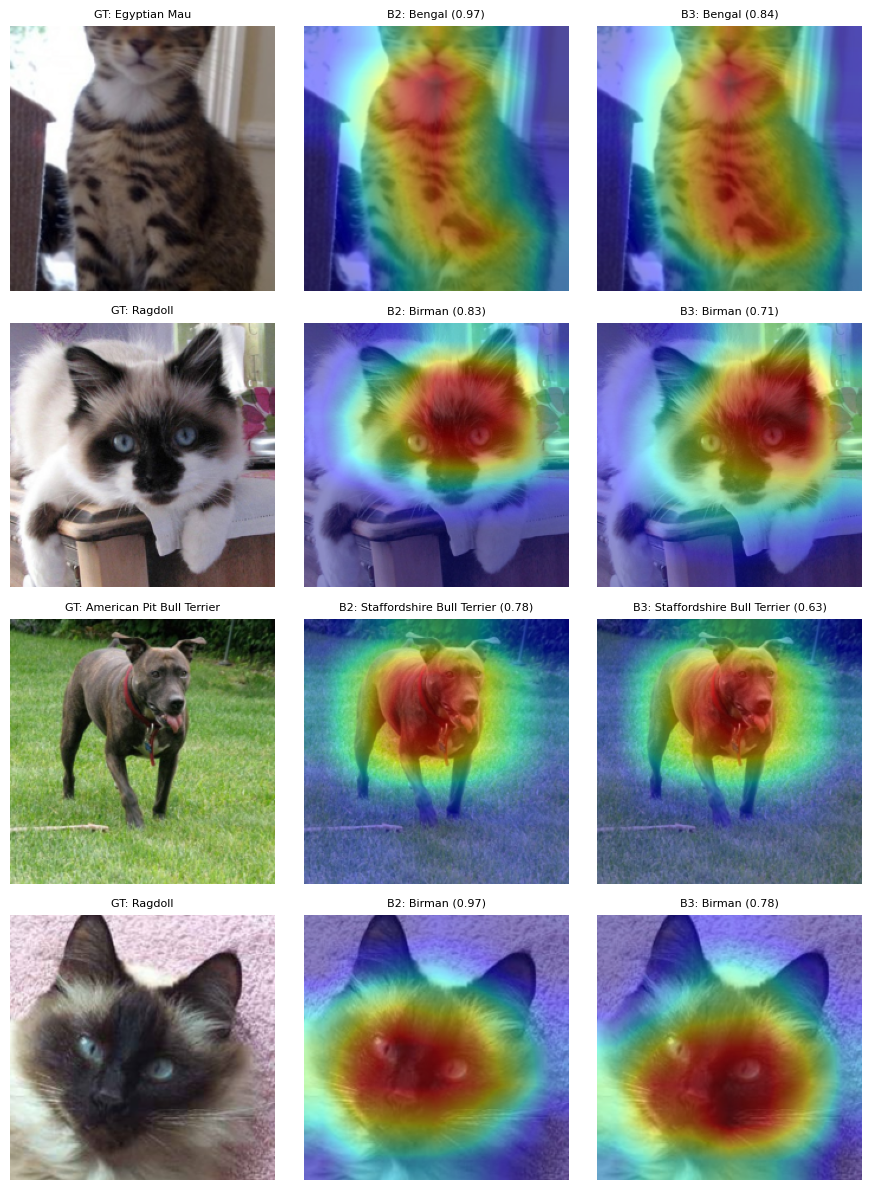

In [27]:
def gradcam(model, x):
  model.eval(); store = {}
  h = model.layer4.register_forward_hook(lambda m_, i_, o_: store.__setitem__("a", o_))
  x = x.unsqueeze(0).to(device).requires_grad_(True)   # agar graph terbentuk walau backbone beku
  logits = model(x); h.remove()
  k = logits.argmax(1).item(); a = store["a"]          # (1, 512, 7, 7)
  g = torch.autograd.grad(logits[0, k], a)[0]
  cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
  cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
  cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
  return cam.detach().cpu().numpy(), k, logits.softmax(1)[0, k].item()

pick = idx[:4]
fig, axes = plt.subplots(len(pick), 3, figsize=(9, 3 * len(pick)))
for r_, i in enumerate(pick):
  x, y = test_ds[i]; img = inv(x).clamp(0, 1).permute(1, 2, 0).numpy()
  axes[r_, 0].imshow(img); axes[r_, 0].axis("off"); axes[r_, 0].set_title(f"GT: {CHOSEN[y]}", fontsize=8)
  for col, name in [(1, "B2"), (2, "B3")]:
    cam, k, p = gradcam(out[name]["model"], x)
    axes[r_, col].imshow(img); axes[r_, col].imshow(cam, cmap="jet", alpha=0.45)
    axes[r_, col].axis("off"); axes[r_, col].set_title(f"{name}: {CHOSEN[k]} ({p:.2f})", fontsize=8)
plt.tight_layout(); plt.savefig("gradcam_B2_vs_B3.png", dpi=150); plt.show()

## Cek Confidence B2 vs B3

In [28]:
for n in ["B2", "B3"]:
  tt = out[n]["test"]; conf_t = tt["probs"].max(1).values; is_wrong = tt["preds"] != tt["labels"]
  print(n, "salah:", int(is_wrong.sum()), "| conf rata-rata salah:", round(conf_t[is_wrong].mean().item(), 3),
        "| conf rata-rata benar:", round(conf_t[~is_wrong].mean().item(), 3))

B2 salah: 32 | conf rata-rata salah: 0.676 | conf rata-rata benar: 0.882
B3 salah: 31 | conf rata-rata salah: 0.739 | conf rata-rata benar: 0.924


# Export Log & Summary Table


In [29]:
# file pendukung log
print(torch.__version__, torchvision.__version__)
for k in ["B3", "B5_efficientnet_b0", "B5_mobilenet_v3_small"]:
  print(k, round(RESULTS[k]["latency_ms_b32"], 1), "ms / batch 32")

def row(label, key, strategi):
  r = RESULTS[key]
  return {"Kondisi": label, "Strategi": strategi,
          "Trainable": r["trainable_params"], "Total": r["total_params"],
          "LR": "/".join(f"{x:g}" for x in r["lr_per_group"]),
          "Best ep": r["best_epoch"], "Epoch run": r["epochs_run"],
          "Waktu (s)": r["train_time_sec"],
          "s/epoch": round(r["train_time_sec"] / r["epochs_run"], 1),
          "Train acc": round(r["train_acc_clean"], 3), "Val acc": round(r["val_acc"], 3),
          "Test F1": round(r["test_macro_f1"], 3), "Gap": round(r["gap_train_val"], 3),
          "Latensi ms/b32": round(r["latency_ms_b32"], 1) if "latency_ms_b32" in r else None}

summary = pd.DataFrame([
  row("B1", "B1", "Scratch (patience 5)"),
  row("B1_ext", "B1_ext", "Scratch (patience 10, run tambahan)"),
  row("B2", "B2", "Feature extraction"),
  row("B3", "B3", "Fine-tune layer4 + aug"),
  row("B4", "B4_B3_noaug", "B3 tanpa augmentasi"),
  row("B5a", "B5_efficientnet_b0", "EfficientNet-B0"),
  row("B5b", "B5_mobilenet_v3_small", "MobileNetV3-S"),
])
print(summary.to_string(index=False))

EXTRA = {"mcnemar_B2_vs_B3": {"b2_right_b3_wrong": b_cnt, "b2_wrong_b3_right": c_cnt,
                              "p_value": float(mc_p)},
         "failure_model": best_name, "n_wrong": int(len(wrong_idx)),
         "top_confusions": [[n_err, a, b_] for n_err, a, b_ in sorted(pairs, reverse=True)[:6]]}
json.dump(EXTRA, open("analysis_extra.json", "w"), indent=2)
summary.to_csv("results_summary.csv", index=False)
df.to_csv("results_multiseed.csv", index=False)
save_results()

2.11.0+cu130 0.26.0+cu130
B3 31.7 ms / batch 32
B5_efficientnet_b0 40.6 ms / batch 32
B5_mobilenet_v3_small 8.3 ms / batch 32
Kondisi                            Strategi  Trainable    Total           LR  Best ep  Epoch run  Waktu (s)  s/epoch  Train acc  Val acc  Test F1   Gap  Latensi ms/b32
     B1                Scratch (patience 5)   11181642 11181642        0.001       13         18      266.5     14.8      0.452    0.399    0.411 0.053             NaN
 B1_ext Scratch (patience 10, run tambahan)   11181642 11181642        0.001       39         49      718.9     14.7      0.689    0.514    0.504 0.176             NaN
     B2                  Feature extraction       5130 11181642        0.001       14         19      261.1     13.7      0.941    0.885    0.892 0.055             NaN
     B3              Fine-tune layer4 + aug    8398858 11181642 0.0001/0.001        4          9      125.4     13.9      0.979    0.902    0.895 0.077            31.7
     B4                 B3 tanpa a

In [30]:
ex = json.load(open("analysis_extra.json"))
print("n_wrong:", ex["n_wrong"], "(harus 28) | model:", ex["failure_model"],
      "| p-value:", ex["mcnemar_B2_vs_B3"]["p_value"])
assert ex["n_wrong"] == 28

n_wrong: 28 (harus 28) | model: B5_efficientnet_b0 | p-value: 1.0


In [31]:
import os, shutil
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
for f in ["config.json", "results.json", "results_summary.csv",
          "results_multiseed.csv", "analysis_extra.json"]:
    shutil.copy(f, "results/")
for f in ["curves_B1_B2_B3.png", "curves_B4.png", "failure_analysis.png",
          "crop_check.png", "gradcam_B2_vs_B3.png"]:
    shutil.copy(f, "figures/")

!zip -r hasil.zip results figures
from google.colab import files
files.download("hasil.zip")

  adding: results/ (stored 0%)
  adding: results/results_summary.csv (deflated 45%)
  adding: results/results_multiseed.csv (deflated 48%)
  adding: results/analysis_extra.json (deflated 59%)
  adding: results/results.json (deflated 82%)
  adding: results/config.json (deflated 40%)
  adding: figures/ (stored 0%)
  adding: figures/curves_B1_B2_B3.png (deflated 9%)
  adding: figures/crop_check.png (deflated 0%)
  adding: figures/gradcam_B2_vs_B3.png (deflated 0%)
  adding: figures/curves_B4.png (deflated 11%)
  adding: figures/failure_analysis.png (deflated 0%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>